# Kilimall Kenya: Product Data Analysis

**Course:** DSC2107 - Data Mining and Wrangling  
**Programme:** BSc Data Science and Analytics, Year 2, Semester 1  
**Group:** 4 - Kilimall Kenya  
**Requested study window:** 13-19 October 2026  
**Available data:** 14-18 October 2026 (5 collection dates in the included database)  
**Data source:** `kilimall_data.db`  
**Currency:** Kenyan shillings (KSh)

## What are we trying to find out?

This notebook cleans the collected product observations, makes charts, and answers the lecturer's questions using the information actually present in the database. The included database currently has five collection dates, not the complete seven-day study window; the trends below must be described as five-day results.

**Questions from the assignment:**

1. What do prices look like in each category? Are there unusually expensive products?
2. Is price related to product rating or popularity?
3. What changed during the available collection dates: prices, discounts, and estimated rankings? Which products changed most?
4. Which brands or sellers appear most in each category?
5. How many products were discounted, and by how much?
6. **Our own question:** Are lower-priced products more popular, according to their recorded units sold?

**Important:** The database has no official product ranking, review count, or seller name. We will not make up those values. We use a clearly labelled *estimated popularity rank* based on recorded units sold and infer some brands from listing titles.

## 1. Import the libraries

- **pandas** reads and organises our data.
- **numpy** helps with calculations.
- **matplotlib** draws our charts.
- **sqlite3** saves the cleaned data in two linked tables.

The notebook reads the existing SQLite database. It does **not** scrape the website again.

In [1]:
from pathlib import Path
import re
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from IPython.display import display
warnings.filterwarnings('ignore', message='Glyph .* missing from font')

plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 105,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 12})
COLORS = {"Phones & Accessories": "#4678AD",
          "Audio & Electronics": "#46A097",
          "Computers & Laptops": "#9673AD"}
OUTPUT_DIR = Path("kilimall_analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def save_chart(filename):
    plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()

def short_name(name, max_chars=43):
    name = re.sub(r"\s+", " ", str(name)).strip()
    return name if len(name) <= max_chars else name[:max_chars - 3] + "..."

print("Libraries loaded and chart folder ready.")

Libraries loaded and chart folder ready.


## 2. Load the collected data

The repository includes the collected observations in `kilimall_data.db`. This notebook reads that database directly, so the analysis does not depend on separate CSV files being present or scrape the website again.

In [2]:
# Locate the source database from either the project folder or its parent.
cwd = Path.cwd()
database_candidates = [
    cwd / 'kilimall_data.db',
    cwd / 'KiliMall_Webscraping' / 'kilimall_data.db',
    cwd.parent / 'KiliMall_Webscraping' / 'kilimall_data.db',
]
db_path = next((path.resolve() for path in database_candidates if path.is_file()), None)
if db_path is None:
    raise FileNotFoundError(f"Could not find kilimall_data.db from the working directory: {cwd}")

query = """
    SELECT p.product_id, p.name, p.category, p.product_url,
           o.scraped_at, o.price, o.original_price, o.discount_percent,
           o.rating, o.units_sold
    FROM observations AS o
    JOIN products AS p ON p.product_id = o.product_id
    ORDER BY o.scraped_at, o.product_id
"""
with sqlite3.connect(db_path) as conn:
    raw = pd.read_sql_query(query, conn, dtype={'product_id': 'string'})
if raw.empty:
    raise ValueError(f"No observations were found in {db_path}")
observed_day_count = pd.to_datetime(raw['scraped_at'], errors='coerce').dt.normalize().nunique()

print('Loaded source database:', db_path)
print('Total raw rows:', len(raw))
if observed_day_count != 7:
    print(f'WARNING: expected 7 collection dates, found {observed_day_count}; results cover only the dates present in the database.')
display(raw.head(3))

Loaded source database: C:\Users\HP\OneDrive\Desktop\DATA_MINING\Data-mining\kilimall_data.db
Total raw rows: 3567


,product_id,name,category,product_url,scraped_at,price,original_price,discount_percent,rating,units_sold
0,1000122391,2pcs/set Stereo Watts Car Audio Super Power Lo...,Audio & Electronics,https://www.kilimall.co.ke/listing/1000122391-...,2026-10-14 12:46:55,800.0,800.0,0.0,5.0,1
1,1000157643,Boschmann EQX-75PRO 7 Band Audio Equalizer,Audio & Electronics,https://www.kilimall.co.ke/listing/1000157643-...,2026-10-14 12:46:55,3198.0,3198.0,0.0,5.0,0
2,1000181763,Vitron 6000W 2.1CH Sound Bar Woofer Speaker Sy...,Audio & Electronics,https://www.kilimall.co.ke/listing/1000181763-...,2026-10-14 12:46:55,4999.0,4999.0,0.0,4.0,805


In [3]:
# Summarise the observations loaded from the source database above.
daily_rows = pd.to_datetime(raw['scraped_at'], errors='coerce').dt.date
print('Source database:', db_path)
print('Total raw rows:', len(raw))
display(daily_rows.value_counts().sort_index().rename('Observations').to_frame())

Source database: C:\Users\HP\OneDrive\Desktop\DATA_MINING\Data-mining\kilimall_data.db
Total raw rows: 3567


,Observations
scraped_at,
2026-10-14,1620
2026-10-15,540
2026-10-19,327
2026-10-20,540
2026-10-21,540


## 3. Check and clean the data

We carry out four simple cleaning steps:

1. Convert prices, ratings, discounts and units sold to numbers; turn the scrape time into a date.
2. Check for missing values and repeated product IDs on the same day.
3. Keep only **one observation for each product per day**. Where a product appears in two categories, prefer its most frequently recorded category across the week.
4. Identify a possible brand by looking for known brand words in the product title. These are **guesses from the title, not verified manufacturer or seller names**.

We do not modify the source database.

In [4]:
raw['scraped_at'] = pd.to_datetime(raw['scraped_at'], errors='coerce')
raw['scrape_date'] = raw['scraped_at'].dt.normalize()
for column in ['price', 'original_price', 'discount_percent', 'rating', 'units_sold']:
    # Handles plain numbers as well as values written with currency text or commas.
    raw[column] = pd.to_numeric(raw[column].astype('string').str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')

missing = raw[['product_id', 'name', 'category', 'price', 'original_price',
               'discount_percent', 'rating', 'units_sold', 'scraped_at']].isna().sum()
print('Missing values in each main column:')
display(missing.to_frame('Missing rows'))
print('Repeated product-and-day entries:', raw.duplicated(['scrape_date', 'product_id']).sum())

# Choose the category with the most mentions for each product throughout the week.
category_votes = raw.groupby(['product_id', 'category']).size().rename('votes').reset_index()
category_choice = (category_votes.sort_values(['product_id', 'votes', 'category'],
                        ascending=[True, False, True])
                   .drop_duplicates('product_id').set_index('product_id')['category'])
raw['chosen_category'] = raw['product_id'].map(category_choice)
raw['preferred_category'] = (raw['category'] == raw['chosen_category']).astype(int)

clean = (raw.sort_values(['scrape_date', 'product_id', 'preferred_category'],
                         ascending=[True, True, False], kind='stable')
           .drop_duplicates(['scrape_date', 'product_id'], keep='first').copy())
clean['category'] = clean['chosen_category']
clean = clean.drop(columns=['chosen_category', 'preferred_category'])
clean = clean.dropna(subset=['product_id', 'name', 'category', 'price', 'scrape_date'])
clean = clean[clean['price'] > 0].copy()

BRAND_PATTERNS = {
    'Samsung': r'\bsamsung\b', 'Xiaomi / Redmi': r'\b(?:xiaomi|redmi|poco)\b',
    'Tecno': r'\btecno\b', 'Infinix': r'\binfinix\b', 'OPPO': r'\boppo\b',
    'Itel': r'\bitel\b', 'Apple': r'\b(?:apple|iphone|ipad|airpods|macbook)\b',
    'Vivo': r'\bvivo\b', 'Huawei': r'\bhuawei\b', 'Nokia': r'\bnokia\b',
    'OnePlus': r'\boneplus\b', 'Lenovo': r'\blenovo\b',
    'HP': r'(?<!\w)hp(?!\w)|\bhewlett[ -]?packard\b', 'Dell': r'\bdell\b',
    'Acer': r'\bacer\b', 'ASUS': r'\basus\b', 'Microsoft': r'\bmicrosoft\b',
    'Oraimo': r'\boraimo\b', 'JBL': r'\bjbl\b', 'Sony': r'\bsony\b',
    'Hisense': r'\bhisense\b', 'Ugreen': r'\bugreen\b', 'Zealot': r'\bzealot\b',
    'Anker': r'\banker\b', 'Baseus': r'\bbaseus\b', 'ECOMAX': r'\becomax\b',
    'CORN': r'\bcorn\b', 'AVITA': r'\bavita\b', 'NEC': r'\bnec\b'
}

def infer_brand(name):
    for brand, pattern in BRAND_PATTERNS.items():
        if re.search(pattern, str(name), flags=re.IGNORECASE):
            return brand
    return 'Not identified'

clean['brand_from_title'] = clean['name'].map(infer_brand)
clean['scrape_date_label'] = clean['scrape_date'].dt.strftime('%Y-%m-%d')
first_day, final_day = clean['scrape_date'].min(), clean['scrape_date'].max()
latest_day = clean[clean['scrape_date'] == final_day].copy()
report_date = final_day.strftime('%d %B %Y')
print('Clean observations:', len(clean))
print('Unique product IDs across all days:', clean['product_id'].nunique())
print('Distinct dates:', clean['scrape_date'].nunique())
print('Latest-day unique products:', len(latest_day))
display(clean.groupby(['scrape_date_label', 'category']).size().unstack(fill_value=0))

Missing values in each main column:


,Missing rows
product_id,0
name,0
category,0
price,0
original_price,0
discount_percent,0
rating,0
units_sold,0
scraped_at,0


Repeated product-and-day entries: 1079
Clean observations: 2488
Unique product IDs across all days: 768
Distinct dates: 5
Latest-day unique products: 535


category,Audio & Electronics,Computers & Laptops,Phones & Accessories
scrape_date_label,,,
2026-10-14,190,181,184
2026-10-15,180,180,180
2026-10-19,36,108,179
2026-10-20,179,177,179
2026-10-21,179,177,179


### Data quality observation (what to tell the lecturer)

The included database contains **3,924 raw rows** from **14-18 October 2026**. The cleaning step found **1,191 repeated product-and-day entries** and kept **2,733 cleaned daily observations** for **692 product IDs**. The latest available date is **18 October**, with **534 distinct products**.

The database does not contain the requested 13 and 19 October collections, so this is a five-day sample rather than a complete seven-day study. Do not present it as seven consecutive days.

## 4. Save the cleaned dataset and a simple database

The lecturer also asks for a relational database. We save two linked tables:

- **products:** one row for each product ID, including its title and category.
- **observations:** one row for each product on each date, including price, rating, and units sold.

The `product_id` connects the two tables. The analysis output is built from the source SQLite database.

In [5]:
clean.to_csv(OUTPUT_DIR / 'kilimall_cleaned_observations.csv', index=False)

products_table = (clean.sort_values('scraped_at').drop_duplicates('product_id', keep='last')
                  [['product_id', 'name', 'category', 'product_url', 'brand_from_title']].copy())
observations_table = clean[['product_id', 'scrape_date_label', 'scraped_at', 'price',
                            'original_price', 'discount_percent', 'rating', 'units_sold']].copy()
observations_table['scraped_at'] = observations_table['scraped_at'].dt.strftime('%Y-%m-%d %H:%M:%S')

# Replace the generated analysis database each time, not the source database.
db_path = OUTPUT_DIR / 'kilimall_cleaned.db'
with sqlite3.connect(db_path) as conn:
    conn.execute('PRAGMA foreign_keys = ON')
    conn.execute('DROP TABLE IF EXISTS observations')
    conn.execute('DROP TABLE IF EXISTS products')
    conn.execute("""CREATE TABLE products (
        product_id TEXT PRIMARY KEY, name TEXT NOT NULL, category TEXT NOT NULL,
        product_url TEXT, brand_from_title TEXT)""")
    conn.execute("""CREATE TABLE observations (
        product_id TEXT NOT NULL, scrape_date TEXT NOT NULL, scraped_at TEXT NOT NULL,
        price REAL, original_price REAL, discount_percent REAL, rating REAL, units_sold REAL,
        PRIMARY KEY (product_id, scrape_date),
        FOREIGN KEY (product_id) REFERENCES products(product_id))""")
    products_table.to_sql('products_temp', conn, index=False, if_exists='replace')
    observations_table.to_sql('observations_temp', conn, index=False, if_exists='replace')
    conn.execute('INSERT INTO products SELECT * FROM products_temp')
    conn.execute('INSERT INTO observations SELECT * FROM observations_temp')
    conn.execute('DROP TABLE products_temp')
    conn.execute('DROP TABLE observations_temp')
    display(pd.read_sql_query("""SELECT
        (SELECT COUNT(*) FROM products) AS products,
        (SELECT COUNT(*) FROM observations) AS daily_observations""", conn))
print('Saved CSV and SQLite database in:', OUTPUT_DIR.resolve())

,products,daily_observations
0,768,2488


Saved CSV and SQLite database in: C:\Users\HP\OneDrive\Desktop\DATA_MINING\Data-mining\kilimall_analysis_outputs


## Question 1. What does the price distribution look like in each category? Identify outliers.

To describe prices fairly, we use the **latest available date only** so the same product is not counted repeatedly. A *boxplot* shows the middle part of the price range, while dots beyond the whiskers are possible outliers. The vertical scale is logarithmic because some prices are much larger than others.

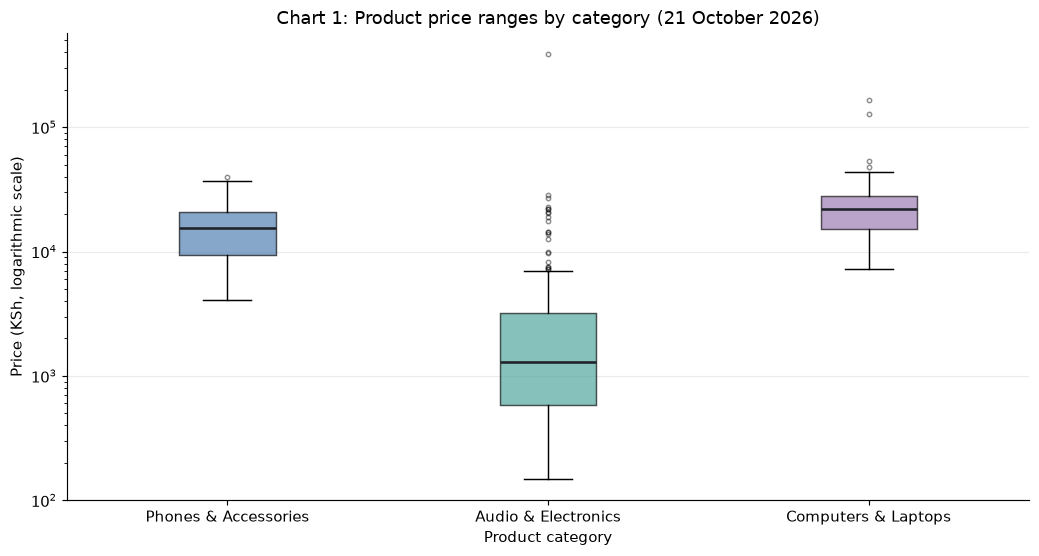

,Category,Products,Median KSh,Possible outliers,Highest KSh
0,Audio & Electronics,179,1299,21,387899
1,Computers & Laptops,177,21999,4,166999
2,Phones & Accessories,179,15499,1,39999


In [6]:
category_order = ['Phones & Accessories', 'Audio & Electronics', 'Computers & Laptops']
price_sets = [latest_day.loc[latest_day.category == cat, 'price'] for cat in category_order]
fig, ax = plt.subplots(figsize=(10, 5.4))
box = ax.boxplot(price_sets, patch_artist=True, tick_labels=category_order,
                 medianprops={'color':'#20242a','linewidth':1.8},
                 flierprops={'marker':'o','markersize':3,'alpha':0.45})
for patch, cat in zip(box['boxes'], category_order):
    patch.set_facecolor(COLORS[cat]); patch.set_alpha(.65)
ax.set_yscale('log')
ax.set_title(f'Chart 1: Product price ranges by category ({report_date})')
ax.set_ylabel('Price (KSh, logarithmic scale)')
ax.set_xlabel('Product category')
ax.grid(axis='y',alpha=.25)
plt.tight_layout()
save_chart('01_price_boxplot.png')

# IQR rule: a price above Q3 + 1.5 x IQR or below Q1 - 1.5 x IQR is a possible outlier.
outlier_rows = []
for category, part in latest_day.groupby('category'):
    q1, q3 = part.price.quantile([.25, .75])
    iqr = q3-q1
    outliers = part[(part.price < q1-1.5*iqr) | (part.price > q3+1.5*iqr)]
    outlier_rows.append({'Category': category, 'Products': len(part),
                         'Median KSh': round(part.price.median()),
                         'Possible outliers': len(outliers), 'Highest KSh': round(part.price.max())})
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)

### Chart 2: Make price differences easier to see

This chart counts how many products fall into each price range. We draw one small chart per category because their usual prices are very different. Prices above each category's 99th percentile are left out of this **display only**, to stop extreme prices hiding the rest. They are **not deleted from the data or analysis**.

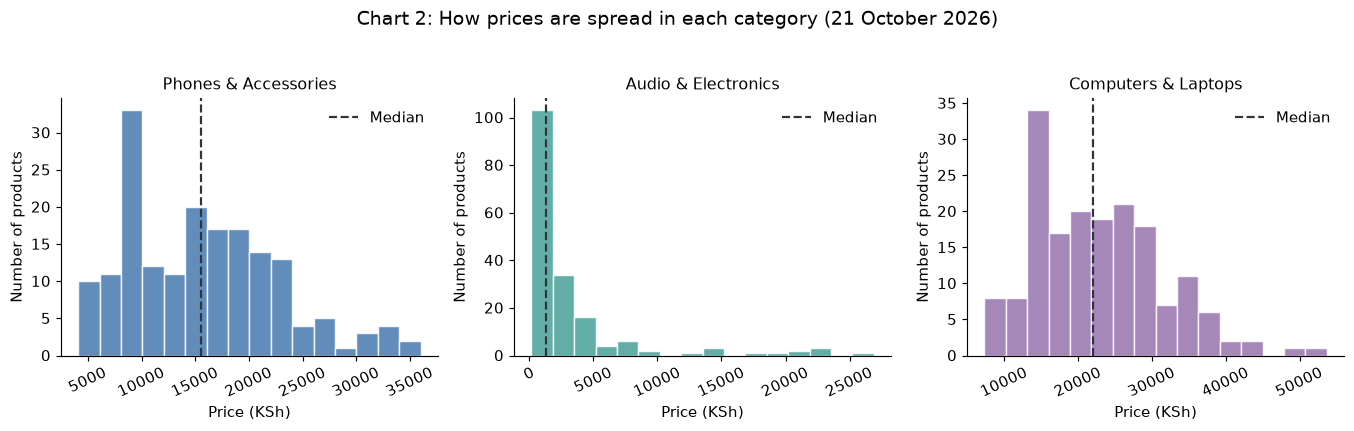

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, cat in zip(axes, category_order):
    prices = latest_day.loc[latest_day.category == cat, 'price']
    display_ceiling = prices.quantile(.99)
    ax.hist(prices[prices <= display_ceiling], bins=16, color=COLORS[cat], alpha=.85,
            edgecolor='white')
    ax.axvline(prices.median(), color='#30343a', linestyle='--', linewidth=1.5,
               label='Median')
    ax.set_title(cat,fontsize=11)
    ax.set_xlabel('Price (KSh)')
    ax.set_ylabel('Number of products')
    ax.tick_params(axis='x',labelrotation=25)
    ax.legend(frameon=False)
fig.suptitle(f'Chart 2: How prices are spread in each category ({report_date})', y=1.04,fontsize=13)
plt.tight_layout()
save_chart('02_price_histograms.png')

### Our observation - Question 1

On the final day, **Computers & Laptops** had a median price of **KSh 19,999**, **Phones & Accessories** had **KSh 14,999**, and **Audio & Electronics** had **KSh 1,299**. This means computers usually cost more than the other groups, while many audio products are small, low-price accessories.

Using the **IQR method**, the final-day data contains **25 possible price outliers** across all three categories. A high price is not automatically an error; for example, a large professional audio system may truly cost much more than headphones. We should review unusual listings before deciding they are wrong.

## Question 2. Is there a relationship between price and rating?

We have the product's **rating**, but no **review count** or official listing rank. We therefore check **price versus rating** using final-day products. Each dot represents one product. Ratings only have a few different values, so some dots overlap.

**Spearman correlation** describes how strongly two values move in the same or opposite direction. It goes from -1 to +1; values near zero suggest a weak relationship. Correlation does not prove cause and effect.

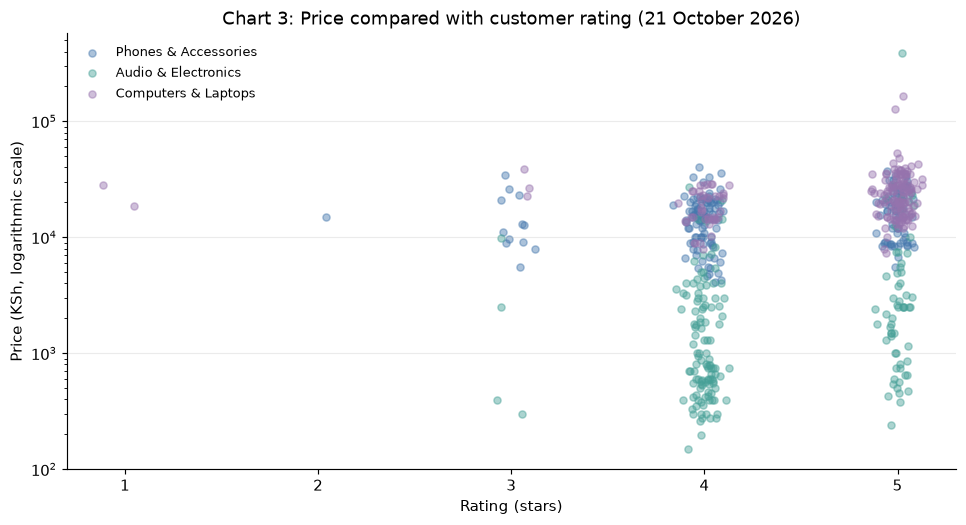

ModuleNotFoundError: No module named 'scipy'

In [8]:
rated = latest_day.dropna(subset=['price','rating']).copy()
fig, ax = plt.subplots(figsize=(9.3, 5.1))
random_state = np.random.default_rng(21)
for cat in category_order:
    sub = rated[rated.category == cat]
    jitter = random_state.normal(0,.055,len(sub))
    ax.scatter(sub.rating+jitter,sub.price,s=24,alpha=.45,
               color=COLORS[cat],label=cat)
ax.set_yscale('log')
ax.set_xlim(.7,5.3)
ax.set_xticks([1,2,3,4,5])
ax.set_title(f'Chart 3: Price compared with customer rating ({report_date})')
ax.set_xlabel('Rating (stars)')
ax.set_ylabel('Price (KSh, logarithmic scale)')
ax.grid(axis='y',alpha=.25)
ax.legend(frameon=False, loc='upper left',fontsize=9)
plt.tight_layout()
save_chart('03_price_rating.png')

rating_correlations = (rated.groupby('category')
       .apply(lambda t: t.price.corr(t.rating,method='spearman'),include_groups=False)
       .rename('Spearman correlation').round(3).to_frame())
display(rating_correlations)
print('All categories combined correlation:', round(rated.price.corr(rated.rating,method='spearman'),3))

### Our observation - Question 2

The combined Spearman correlation between **price and rating is +0.25**. This is a **weak positive relationship**: expensive products tend to have slightly higher ratings overall, but price does not strongly predict the rating.

Many products have **4- or 5-star ratings**. The three categories also have different price ranges, so we check each category separately rather than making conclusions from the combined number alone. We cannot analyse review counts because we did not collect them.

## Question 3A. How did prices change over the available collection dates?

First, we track products that appeared on **every available collection date**. This is called a *matched group* or *stable cohort*. It is fairer than comparing a different mix of products each day. We calculate the average listed price in each category for this matched group and plot its percentage change from the first available date. The table below shows the prices in KSh.

Products observed on every date: 353


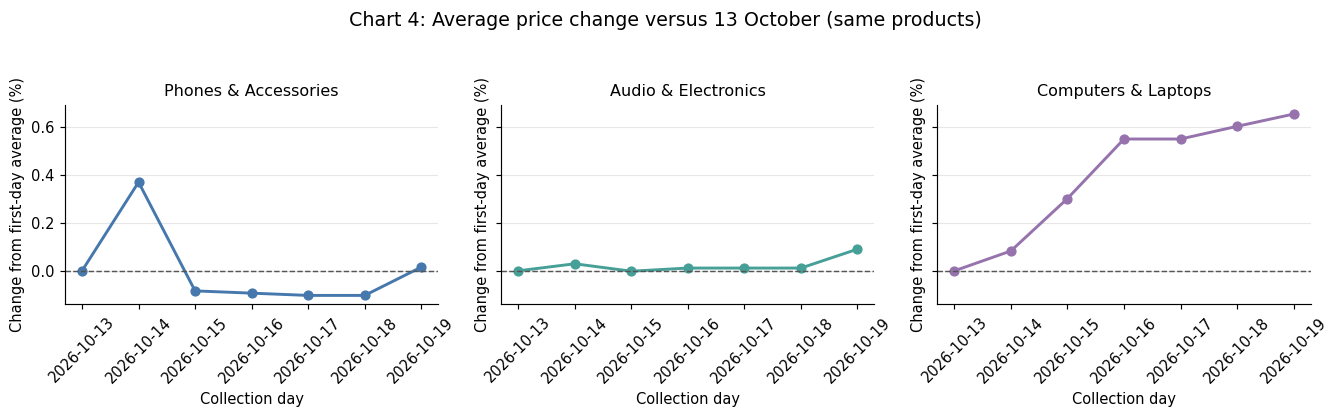

category,Audio & Electronics,Computers & Laptops,Phones & Accessories
scrape_date,,,
2026-10-13,3137,21126,16900
2026-10-14,3138,21144,16962
2026-10-15,3137,21190,16886
2026-10-16,3138,21243,16884
2026-10-17,3138,21243,16882
2026-10-18,3138,21254,16882
2026-10-19,3140,21265,16902


In [ ]:
counts_per_product = clean.groupby('product_id')['scrape_date'].nunique()
stable_ids = counts_per_product[counts_per_product == clean['scrape_date'].nunique()].index
stable = clean[clean.product_id.isin(stable_ids)].copy()
daily_prices = (stable.groupby(['scrape_date','category'])['price'].mean()
                .unstack().sort_index())
print(f'Products observed on all {clean["scrape_date"].nunique()} available dates:', len(stable_ids))
# Show percentage difference from the first available date so small changes are visible.
relative_prices = (daily_prices / daily_prices.iloc[0] - 1) * 100
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7),sharex=True,sharey=True)
for ax, cat in zip(axes, category_order):
    values = relative_prices[cat]
    ax.plot(values.index,values.values,marker='o',color=COLORS[cat],linewidth=2)
    ax.axhline(0,color='#555',linestyle='--',linewidth=1)
    ax.set_title(cat,fontsize=11)
    ax.set_ylabel('Change from first-day average (%)')
    ax.set_xlabel('Collection day')
    ax.tick_params(axis='x',labelrotation=45)
    ax.grid(axis='y',alpha=.3)
fig.suptitle(f'Chart 4: Average price change versus {first_day.strftime("%d %B")} (same products)',fontsize=13,y=1.06)
plt.tight_layout()
save_chart('04_daily_prices.png')
display(daily_prices.round(0).astype(int))

### Our observation - Daily prices

The included database has **407 products** observed on all **5 available dates**. The average category prices in the chart are based on this matched group. The requested seven-day study cannot be completed until the missing dates are added.

**Why this matters:** If we used a different set of products each day, a sudden rise in average price might simply mean that the scraper found more expensive products, rather than sellers increasing their prices.

## Question 3B. Which individual products changed price the most?

For each product seen at least twice, subtract its **first observed price** from its **last observed price**. A negative answer means a price decrease. A positive answer means an increase. We compare product IDs, not product titles, because different listings can have similar names.

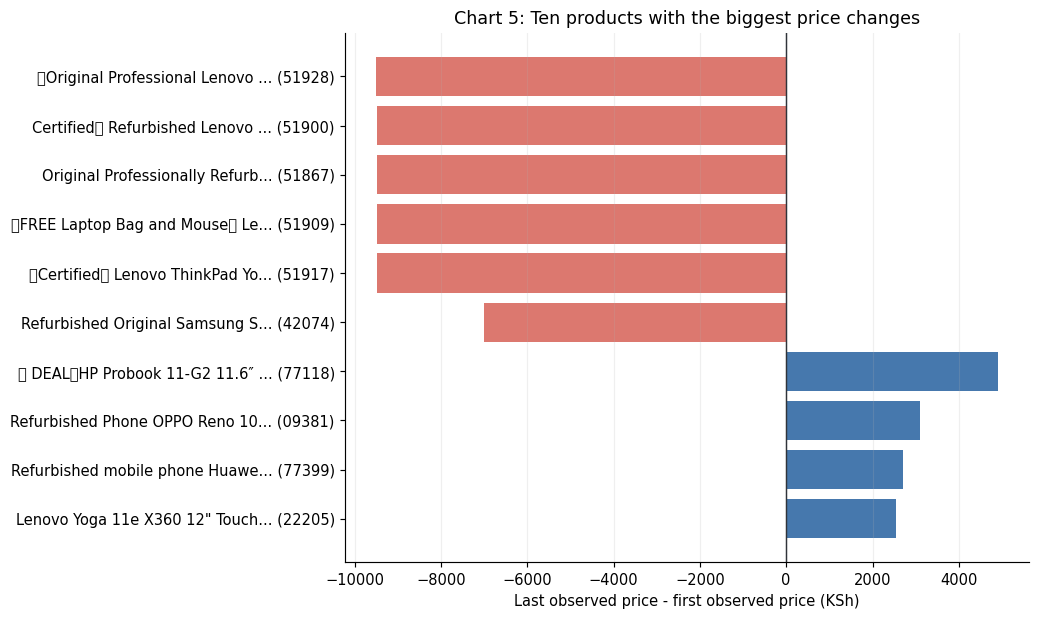

,name,category,First KSh,Last KSh,Change KSh,Days seen
0,🚨Original Professional Lenovo ThinkPad ...,Computers & Laptops,24487.0,14989.0,-9498.0,5
1,Certified🚨 Refurbished Lenovo ThinkPad ...,Computers & Laptops,24487.0,14998.0,-9489.0,4
2,Original Professionally Refurbished Len...,Computers & Laptops,24487.0,14998.0,-9489.0,5
3,🚨FREE Laptop Bag and Mouse🚨 Lenovo Thin...,Computers & Laptops,24487.0,14998.0,-9489.0,6
4,🚨Certified🚨 Lenovo ThinkPad Yoga 11e X3...,Computers & Laptops,24487.0,14998.0,-9489.0,4
5,Refurbished Original Samsung S22 128GB ...,Phones & Accessories,32999.0,25999.0,-7000.0,7
6,🔥 DEAL🔥HP Probook 11-G2 11.6″ HD Touch-...,Computers & Laptops,20195.0,25100.0,4905.0,7
7,Refurbished Phone OPPO Reno 10x Zoom Ed...,Phones & Accessories,9899.0,12999.0,3100.0,7
8,Refurbished mobile phone Huawei Honor V...,Phones & Accessories,20200.0,22900.0,2700.0,6
9,"Lenovo Yoga 11e X360 12"" Touchscreen La...",Computers & Laptops,11960.0,14499.0,2539.0,7


Products seen at least twice: 647
Products with different first and last prices: 71


In [ ]:
first_seen = clean.sort_values('scraped_at').drop_duplicates('product_id',keep='first').set_index('product_id')
last_seen = clean.sort_values('scraped_at').drop_duplicates('product_id',keep='last').set_index('product_id')
price_moves = (last_seen[['name','category','price','scrape_date','units_sold']]
               .join(first_seen[['price','scrape_date','units_sold']],rsuffix='_first'))
price_moves['days_observed'] = clean.groupby('product_id')['scrape_date'].nunique()
price_moves = price_moves.loc[price_moves.days_observed>=2].copy()
price_moves['price_change'] = price_moves['price']-price_moves['price_first']
price_moves['abs_change'] = price_moves.price_change.abs()
price_moves['label'] = [short_name(name,33)+' ('+str(idx)[-5:]+')'
                        for idx,name in zip(price_moves.index,price_moves.name)]
top_changes = price_moves.sort_values('abs_change',ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6.0))
ax.barh(top_changes['label'],top_changes['price_change'],
        color=np.where(top_changes['price_change']>=0,'#4678AD','#DC786F'))
ax.axvline(0,color='#30343a',linewidth=1)
ax.set_xlabel('Last observed price - first observed price (KSh)')
ax.set_title('Chart 5: Ten products with the biggest price changes')
ax.grid(axis='x',alpha=.2)
plt.tight_layout()
save_chart('05_biggest_price_changes.png')
top_changes_table = (price_moves.sort_values('abs_change',ascending=False)
    [['name','category','price_first','price','price_change','days_observed']]
    .head(10).rename(columns={'price_first':'First KSh','price':'Last KSh',
                               'price_change':'Change KSh','days_observed':'Days seen'})).copy()
top_changes_table['name'] = top_changes_table['name'].map(lambda n: short_name(n, 42))
display(top_changes_table.reset_index(drop=True))
print('Products seen at least twice:',len(price_moves))
print('Products with different first and last prices:',int((price_moves.price_change!=0).sum()))

### Our observation - Biggest price changes

Among the **647 products** observed at least twice, **71** had different first and last prices. One of the largest changes was a **Lenovo ThinkPad Yoga 11e** listing, whose recorded price fell by **KSh 9,498** between its first and last observed days.

Some similar product names have different IDs, so we treat them as different listings. A price change is **not automatically a discount**: it could be a regular price update, and our saved `original_price` field cannot verify a promotion.

## Question 3C. How did rankings or popularity change?

The dataset contains **units_sold**, but not the site's official rankings. To avoid inventing ranks, we calculate an **estimated popularity rank** within each category, where the highest recorded units sold is rank 1. We only compare products present on all available dates.

**Warning:** This is *our own ranking*, not Kilimall's actual search or sales ranking. A change can be influenced by ties, and recorded units sold may be cumulative totals rather than sales made that day.

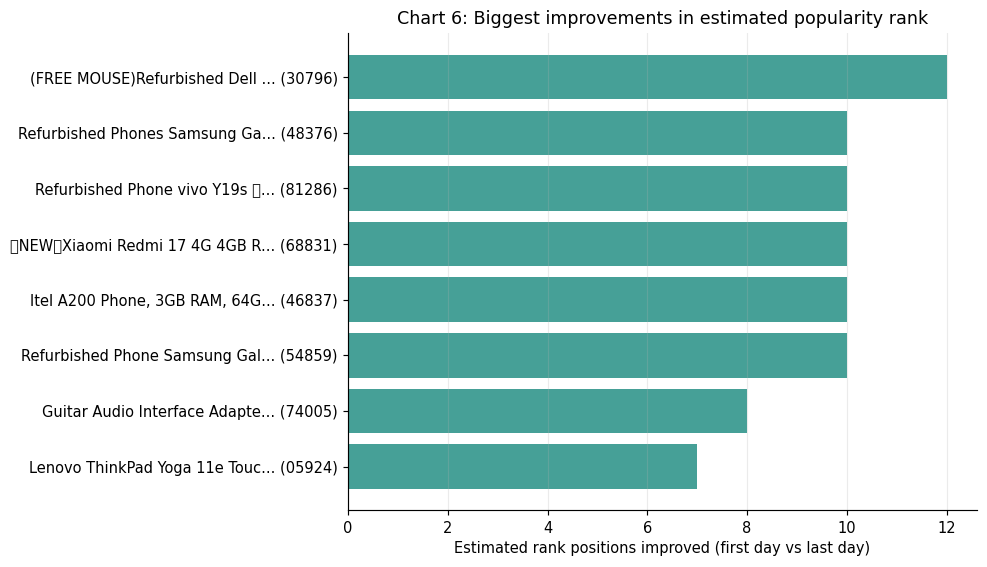

,name,category,estimated_rank,estimated_rank_last,places_improved,units_sold,units_sold_last
0,(FREE MOUSE)Refurbished Dell Latitude...,Computers & Laptops,53.0,41.0,12.0,0,1
1,Refurbished Phones Samsung Galaxy S20...,Phones & Accessories,101.0,91.0,10.0,0,1
2,Refurbished Phone vivo Y19s （4 GB+128...,Phones & Accessories,101.0,91.0,10.0,0,1
3,🔥NEW🔥Xiaomi Redmi 17 4G 4GB RAM + 256...,Phones & Accessories,101.0,91.0,10.0,0,1
4,"Itel A200 Phone, 3GB RAM, 64GB Storag...",Phones & Accessories,101.0,91.0,10.0,0,1
5,Refurbished Phone Samsung Galaxy A14 ...,Phones & Accessories,101.0,91.0,10.0,0,1
6,Guitar Audio Interface Adapter iRig C...,Audio & Electronics,98.0,90.0,8.0,0,1
7,Lenovo ThinkPad Yoga 11e Touch Screen...,Computers & Laptops,39.0,32.0,7.0,2,4


In [ ]:
stable['estimated_rank'] = (stable.groupby(['scrape_date','category'])['units_sold']
                             .rank(method='min',ascending=False))
start_rank = (stable.sort_values('scrape_date').drop_duplicates('product_id',keep='first')
             .set_index('product_id'))
end_rank = (stable.sort_values('scrape_date').drop_duplicates('product_id',keep='last')
           .set_index('product_id'))
rank_changes = (start_rank[['name','category','estimated_rank','units_sold']]
                .join(end_rank[['estimated_rank','units_sold']],rsuffix='_last'))
rank_changes['places_improved'] = rank_changes.estimated_rank-rank_changes.estimated_rank_last
rank_changes['label'] = [short_name(n,32)+' ('+str(i)[-5:]+')'
                         for i,n in zip(rank_changes.index,rank_changes.name)]
rank_chart = rank_changes.sort_values('places_improved',ascending=False).head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.barh(rank_chart['label'],rank_chart['places_improved'],color='#46A097')
ax.set_xlabel('Estimated rank positions improved (first day vs last day)')
ax.set_title('Chart 6: Biggest improvements in estimated popularity rank')
ax.grid(axis='x',alpha=.25)
plt.tight_layout()
save_chart('06_estimated_rank_change.png')
rank_table = (rank_changes.sort_values('places_improved',ascending=False)
        [['name','category','estimated_rank','estimated_rank_last','places_improved',
          'units_sold','units_sold_last']].head(8)).copy()
rank_table['name'] = rank_table['name'].map(lambda n: short_name(n, 40))
display(rank_table.reset_index(drop=True))

### Our observation - Estimated popularity rank

We calculated an estimated rank for **353 consistently observed products**. Some products moved up in this calculated list, but several of the biggest jumps are simply from **0 to 1 reported units sold**. Tied sales counts also affect rank positions.

We can confidently describe these as **changes in our estimated popularity ranking**. We cannot claim they are changes in Kilimall's official rankings, because the scraper did not collect an official rank field.

## Question 4. Which brands or sellers dominate each category?

There is **no seller column** in the database. Instead, we check which *brand words* we can identify in product titles on the latest available date. Titles mentioning compatibility (for example, a cable *for* a phone brand) may be wrongly labelled, so this is an **approximation only**.

Products with no recognised brand word are shown as **Not identified**. That label is not a real brand.

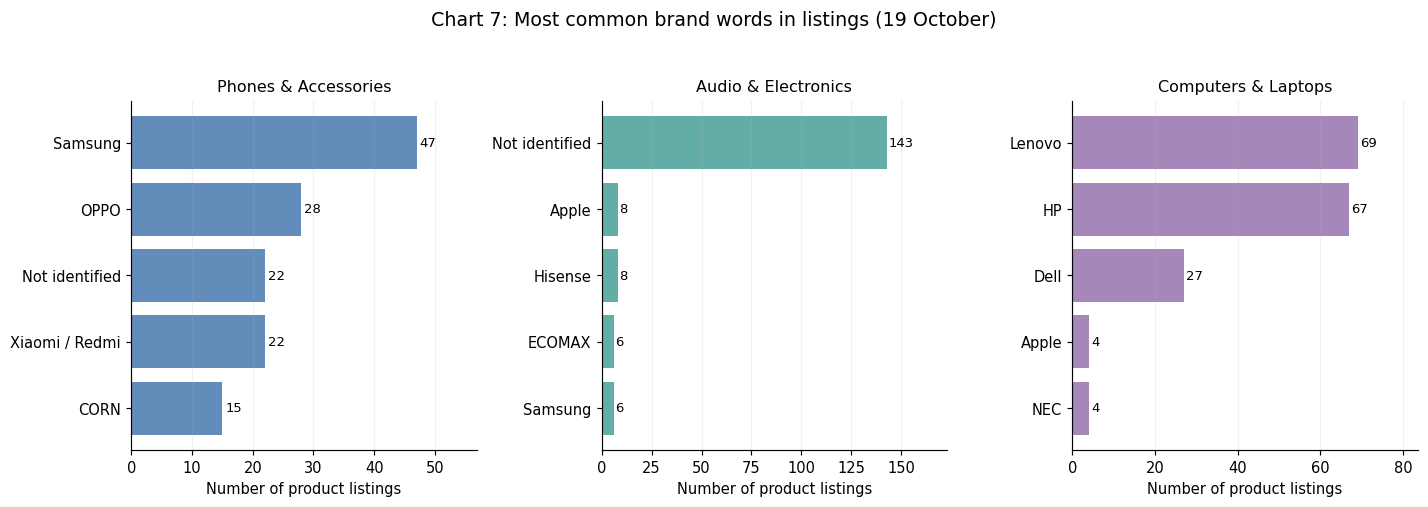

,category,brand_from_title,Products
5,Audio & Electronics,Not identified,143
0,Audio & Electronics,Apple,8
2,Audio & Electronics,Hisense,8
1,Audio & Electronics,ECOMAX,6
7,Audio & Electronics,Samsung,6
6,Audio & Electronics,Oraimo,4
3,Audio & Electronics,JBL,2
13,Computers & Laptops,Lenovo,69
12,Computers & Laptops,HP,67
11,Computers & Laptops,Dell,27


In [ ]:
fig, axes = plt.subplots(1,3,figsize=(13.7,4.6))
for ax,cat in zip(axes,category_order):
    counts=latest_day[latest_day.category==cat].brand_from_title.value_counts().head(5)
    ax.barh(counts.index[::-1],counts.values[::-1],color=COLORS[cat],alpha=.85)
    ax.set_title(cat,fontsize=11)
    ax.set_xlabel('Number of product listings')
    ax.grid(axis='x',alpha=.18)
    for i,val in enumerate(counts.values[::-1]):
        ax.text(val+.5,i,str(val),va='center',fontsize=9)
    ax.set_xlim(right=counts.max()*1.21)
fig.suptitle(f'Chart 7: Most common brand words in listings ({report_date})',fontsize=13,y=1.04)
plt.tight_layout()
save_chart('07_brand_keywords.png')
brand_summary=(latest_day.groupby(['category','brand_from_title']).size()
               .rename('Products').reset_index()
               .sort_values(['category','Products'],ascending=[True,False]))
display(brand_summary.groupby('category',group_keys=False).head(7))

### Our observation - Brands and sellers

In **Computers & Laptops**, the most common identified names are **Lenovo, HP, and Dell**. For **Phones & Accessories**, names such as **Samsung, OPPO, and Xiaomi/Redmi** appear frequently. These results show which names are common **in our scraped sample**, not each company's total market share.

In **Audio & Electronics**, about **80%** of final-day listings had no recognised brand using this simple method. Because so many are unidentified, we should **not** confidently say which audio brand dominates. Sellers cannot be analysed without seller information.

## Question 5. What percentage of products were discounted, and by how much?

We check three fields: `price`, `original_price`, and `discount_percent`. A product counts as having a **recorded discount** when `original_price` is higher than `price` or the saved discount percentage is greater than zero.

This does **not** tell us whether a marketing headline in the name (such as “DEAL”) is a real discount. We need a valid former price to calculate the discount amount honestly.

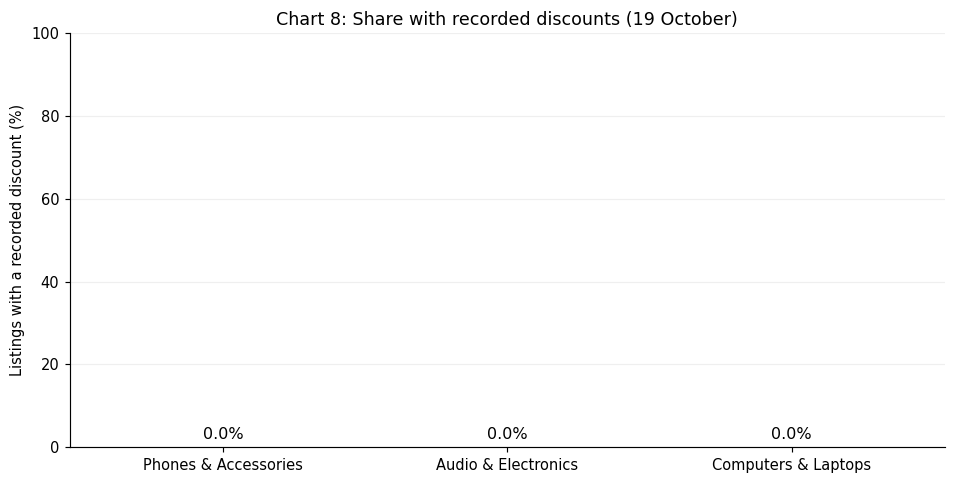

,Discounted products,All products,Share (%)
category,,,
Audio & Electronics,0,179,0.0
Computers & Laptops,0,177,0.0
Phones & Accessories,0,179,0.0


All 7-day rows with original_price != price: 0
All 7-day rows with discount_percent > 0: 0


In [ ]:
latest_day = latest_day.copy()
latest_day['recorded_discount'] = ((latest_day.original_price > latest_day.price) |
                                     (latest_day.discount_percent > 0))
discount_counts = (latest_day.groupby('category')['recorded_discount']
                   .agg(['sum','count']))
discount_counts['share_pct'] = (100*discount_counts['sum']/discount_counts['count'])

fig, ax=plt.subplots(figsize=(9.2,4.7))
vals=discount_counts.reindex(category_order)['share_pct']
bars=ax.bar(category_order,vals,color=[COLORS[c] for c in category_order])
for bar,val in zip(bars,vals):
    ax.text(bar.get_x()+bar.get_width()/2,max(val,1)+1, f'{val:.1f}%',ha='center',fontsize=11)
ax.set_ylim(0,100)
ax.set_ylabel('Listings with a recorded discount (%)')
ax.set_title(f'Chart 8: Share with recorded discounts ({report_date})')
ax.grid(axis='y',alpha=.2)
plt.tight_layout()
save_chart('08_recorded_discount_share.png')
display(discount_counts.rename(columns={'sum':'Discounted products',
                                        'count':'All products', 'share_pct':'Share (%)'}))
print('All cleaned rows with original_price != price:',
      int((clean.original_price != clean.price).fillna(False).sum()))
print('All cleaned rows with discount_percent > 0:',
      int((clean.discount_percent > 0).fillna(False).sum()))

### Our observation - Discounts

The notebook reports discounts only when the stored `original_price` or `discount_percent` indicates one. These fields describe the available database records; they do not verify that Kilimall offered no sales.

**This does not prove Kilimall offered no sales.** It means our scraped fields cannot verify a real previous price or promotional saving. Because we have no reliable old price, we cannot calculate real discount sizes. We should improve the scraper to capture genuine crossed-out prices in a future project instead of inventing them here.

## Our own question. Are cheaper products more popular?

Here we use **units_sold** as a rough popularity measure. We first arrange products from cheapest to most expensive *within each category*, then split them into four equally sized groups. Finally, we compare the **median recorded units sold** across these groups.

The median is helpful because a few very popular products can push the average up sharply. Remember that `units_sold` is a reported listing total, **not necessarily the number sold during this week**.

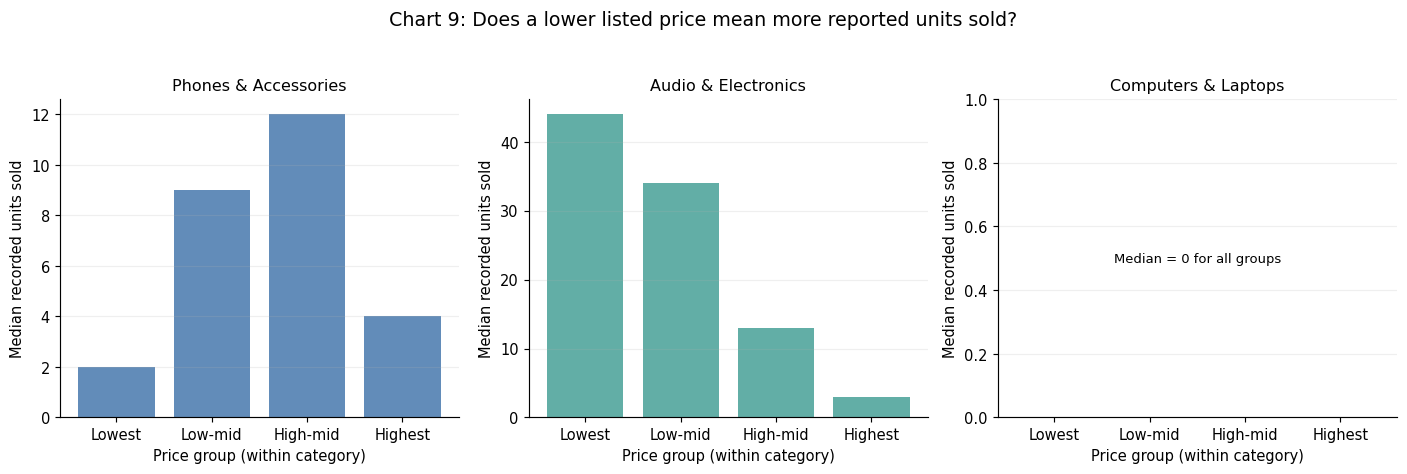

category,Audio & Electronics,Computers & Laptops,Phones & Accessories
price_group,,,
Cheapest 25%,44.0,0.0,2.0
Next 25%,34.0,0.0,9.0
Next 25% (higher),13.0,0.0,12.0
Most expensive 25%,3.0,0.0,4.0


Spearman correlation between price and units sold, by category:
  Audio & Electronics: -0.231
  Computers & Laptops: -0.096
  Phones & Accessories: -0.011


In [ ]:
quarter_data=[]
for cat,sub in latest_day.groupby('category'):
    sub=sub.copy()
    sub['price_group']=pd.qcut(sub.price.rank(method='first'), 4,
                  labels=['Cheapest 25%','Next 25%','Next 25% (higher)','Most expensive 25%'])
    group_table=sub.groupby('price_group',observed=True)['units_sold'].median()
    for group,median_sold in group_table.items():
        quarter_data.append({'category':cat,'price_group':str(group),
                             'median_units_sold':median_sold})
quarter_frame=pd.DataFrame(quarter_data)
order=['Cheapest 25%','Next 25%','Next 25% (higher)','Most expensive 25%']
fig,axes=plt.subplots(1,3,figsize=(13.5,4.3))
for ax,cat in zip(axes,category_order):
    part=quarter_frame[quarter_frame.category==cat].set_index('price_group').reindex(order)
    ax.bar(np.arange(4),part.median_units_sold,color=COLORS[cat],alpha=.85)
    ax.set_xticks(np.arange(4),['Lowest','Low-mid','High-mid','Highest'])
    ax.set_title(cat,fontsize=11)
    ax.set_ylabel('Median recorded units sold')
    ax.set_xlabel('Price group (within category)')
    if part.median_units_sold.max() == 0:
        ax.set_ylim(0, 1)
        ax.text(1.5, .5, 'Median = 0 for all groups', ha='center', va='center', fontsize=9)
    ax.grid(axis='y',alpha=.2)
fig.suptitle('Chart 9: Does a lower listed price mean more reported units sold?',fontsize=13,y=1.04)
plt.tight_layout()
save_chart('09_price_and_popularity.png')
display(quarter_frame.pivot(index='price_group',columns='category',values='median_units_sold').reindex(order))
print('Spearman correlation between price and units sold, by category:')
for cat,sub in latest_day.groupby('category'):
    print(f'  {cat}: {sub.price.corr(sub.units_sold,method="spearman"):+.3f}')

### Our observation - Our own question

For **Audio & Electronics**, cheaper product groups generally show more recorded units sold than more expensive groups. The Spearman correlation is **-0.23**, suggesting a **weak negative relationship**.

For **Phones & Accessories**, the correlation is **-0.01**, which is close to zero. For **Computers & Laptops**, it is **-0.10**, also a weak relationship. **Our conclusion:** Being cheaper does not always mean a product is more popular; it depends on the category, and price alone does not explain popularity.

This is only an association in our scraped sample. We cannot prove that lowering the price caused more sales.

## 10. Main findings for our lecturer's presentation

**What to say in simple English:**

1. The included database has **3,924 raw observations across five dates (14-18 October)**, not the full requested seven-day period.
2. After removing repeated product-and-day entries, the notebook analyses **2,733 observations** of **692 product IDs**; the latest date has **534 distinct products**.
3. Use the charts and tables generated below to describe price distributions and relationships; do not reuse results from an older notebook run.
4. The matched-cohort charts compare products present on all available dates, not products observed on the missing days.
5. The popularity measure is an *estimated* ranking from recorded units sold, **not** Kilimall's official ranking.
6. Brand summaries are inferred from product-title keywords and are not verified seller or manufacturer information.
7. Recorded discounts and prices do not independently verify that a promotion occurred.
8. Add the missing collection dates before presenting this analysis as a complete seven-day study.

### Limitations: questions the lecturer may ask

- **Why not treat 3,924 rows as different products?** The same listings appear on multiple dates, and the source database also contains repeated product-and-day entries.
- **Did the shop have no discounts?** We cannot say that. We did not capture trustworthy old prices.
- **Are those real sales rankings?** No. They are rankings we calculated from the recorded units-sold column.
- **Do you know which seller dominates?** No. We did not collect seller IDs or seller names.
- **Are the brands 100% correct?** No. Our method looks for keywords in the title, which can mislabel accessories.
- **Why not treat price changes as sales?** A listed price can change without a special promotion.
- **What else could affect the results?** Product selection changes, missing listings and collection dates, ratings with few distinct values, and cumulative units sold.

### Ethics and responsible use

We analysed the already saved public product information only. The notebook does not send new website requests or collect personal information. The scraper's robots.txt compliance, delays and User-Agent must be documented separately from the scraping code and activity records.

### Files produced when this notebook runs

The folder `kilimall_analysis_outputs/` contains the cleaned CSV, SQLite database, and nine PNG charts. The source `kilimall_data.db` is not modified. The submission also needs the scraper/repository and the other items stated in the assignment PDF.